# Day 7 — Disease Prevalence Dashboard: Analysis

CDC PLACES county estimates for six chronic conditions (2022–2023). All rates are **crude prevalence, % of adults aged 18+** — model-based estimates from BRFSS survey data, not counted cases. State and national rates are **population-weighted**; a simple mean of county percentages is never used. This notebook runs offline from the committed CSVs.

In [1]:
from pathlib import Path
import json
import pandas as pd

def _find_root():
    """Resolve the project root from this notebook's location."""
    here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
    for cand in [here, *here.parents]:
        if (cand / "data" / "processed" / "prevalence_diabetes.csv").exists():
            return cand
    raise FileNotFoundError("could not find data/processed/prevalence_diabetes.csv")

ROOT = _find_root()
PROCESSED = ROOT / "data" / "processed"
SLUGS = {"DIABETES": "diabetes", "COPD": "copd", "CASTHMA": "asthma",
         "CHD": "chd", "STROKE": "stroke", "OBESITY": "obesity"}
LABELS = {"DIABETES": "Diabetes", "COPD": "COPD", "CASTHMA": "Current asthma",
          "CHD": "Coronary heart disease", "STROKE": "Stroke", "OBESITY": "Obesity"}
record = json.loads((PROCESSED / "data_source.json").read_text())
state = pd.read_csv(PROCESSED / "state_prevalence.csv", dtype={"year": str})
print("source:", record["source"], "| generated:", record["generated_at_utc"])
print("row counts 2023:", {m: record["row_counts"][f"{m}_2023"] for m in SLUGS})
print("row counts 2022:", {m: record["row_counts"][f"{m}_2022"] for m in SLUGS})

source: live | generated: 2026-11-11T14:12:07Z
row counts 2023: {'DIABETES': 2958, 'COPD': 2958, 'CASTHMA': 2958, 'CHD': 2958, 'STROKE': 2958, 'OBESITY': 2958}
row counts 2022: {'DIABETES': 3145, 'COPD': 3145, 'CASTHMA': 3145, 'CHD': 3145, 'STROKE': 3145, 'OBESITY': 3145}


## Q1 — Where is estimated prevalence highest and lowest?

National rates are population-weighted. State rates are population-weighted too — the county median is shown alongside to make the point that a median of counties is not a national rate.

In [2]:
rows = []
for m in SLUGS:
    nat = record["national_weighted_vs_us_row"]
    prev = pd.read_csv(PROCESSED / f"prevalence_{SLUGS[m]}.csv", dtype={"year": str})
    c23 = prev[prev["year"] == "2023"]["data_value"]
    s23 = state[(state["measureid"] == m) & (state["year"] == "2023")].sort_values("state_rate")
    rows.append({
        "Condition": LABELS[m],
        "National 2023 (%)": nat[f"{m}_2023"]["weighted"],
        "County median (%)": round(c23.median(), 1),
        "Top state": f"{s23.iloc[-1]['stateabbr']} {s23.iloc[-1]['state_rate']:.2f}%",
        "Bottom state": f"{s23.iloc[0]['stateabbr']} {s23.iloc[0]['state_rate']:.2f}%",
        "State ratio": round(s23.iloc[-1]["state_rate"] / s23.iloc[0]["state_rate"], 2),
        "County range (%)": f"{c23.min():.1f}–{c23.max():.1f}",
    })
q1 = pd.DataFrame(rows)
q1

,Condition,National 2023 (%),County median (%),Top state,Bottom state,State ratio,County range (%)
0,Diabetes,12.05,13.3,WV 15.88%,DC 7.80%,2.04,4.9–27.1
1,COPD,6.49,8.4,WV 10.63%,DC 4.00%,2.66,3.2–17.6
2,Current asthma,10.21,10.6,ME 12.64%,NJ 8.90%,1.42,7.8–15.3
3,Coronary heart disease,6.28,7.8,WV 8.73%,DC 3.80%,2.30,3.0–13.3
4,Stroke,3.41,4.0,MS 4.55%,UT 2.54%,1.79,1.7–8.4
5,Obesity,33.20,37.9,WV 40.63%,DC 24.70%,1.64,16.7–52.9


In [3]:
# Top-10 / bottom-10 counties for diabetes, 2023 — with estimated cases.
d = pd.read_csv(PROCESSED / "prevalence_diabetes.csv", dtype={"year": str})
d23 = d[d["year"] == "2023"].sort_values("data_value", ascending=False)
print("HIGHEST — diabetes, 2023")
print(d23.head(10)[["locationname", "stateabbr", "data_value", "est_cases"]].to_string(index=False))
print("\nLOWEST — diabetes, 2023")
print(d23.tail(10)[["locationname", "stateabbr", "data_value", "est_cases"]].to_string(index=False))

HIGHEST — diabetes, 2023
locationname stateabbr  data_value  est_cases
      Greene        AL        27.1       1560
     Sharkey        MS        25.2        637
      Tensas        LA        25.1        751
    Randolph        GA        24.9       1197
   Humphreys        MS        24.7       1338
       Perry        AL        24.6       1496
     Bullock        AL        24.6       1938
     Lowndes        AL        24.1       1824
      Wilcox        AL        23.8       1846
   Jefferson        MS        23.6       1280

LOWEST — diabetes, 2023
locationname stateabbr  data_value  est_cases
       Riley        KS         7.2       4314
      Denver        CO         7.1      41869
     Boulder        CO         7.1      19250
  Broomfield        CO         7.1       4372
    Gunnison        CO         7.1       1038
        Utah        UT         6.9      34172
     Douglas        CO         6.8      20139
    Gallatin        MT         6.7       6892
  Chittenden        VT        

## Q2 — Did prevalence move from 2022 to 2023?

Changes use only the 2,956 counties present in both years. Kentucky and Pennsylvania have no 2023 rows, so they are out of this comparison entirely — the national 2022→2023 move is partly compositional and is reported next to the matched-county median for that reason.

In [4]:
rows = []
for m in SLUGS:
    ch = pd.read_csv(PROCESSED / f"change_{SLUGS[m]}.csv")
    nat = record["national_weighted_vs_us_row"]
    rows.append({
        "Condition": LABELS[m],
        "National pp": round(nat[f"{m}_2023"]["weighted"] - nat[f"{m}_2022"]["weighted"], 2),
        "Median county pp": round(ch["pp_change"].median(), 2),
        "% counties up": round((ch["pp_change"] > 0).mean() * 100, 1),
        "% counties down": round((ch["pp_change"] < 0).mean() * 100, 1),
        "Biggest rise": f"{ch.loc[ch['pp_change'].idxmax(), 'locationname']}, "
                        f"{ch.loc[ch['pp_change'].idxmax(), 'stateabbr']} "
                        f"({ch['pp_change'].max():+.2f} pp)",
        "Biggest fall": f"{ch.loc[ch['pp_change'].idxmin(), 'locationname']}, "
                        f"{ch.loc[ch['pp_change'].idxmin(), 'stateabbr']} "
                        f"({ch['pp_change'].min():+.2f} pp)",
    })
pd.DataFrame(rows)

,Condition,National pp,Median county pp,% counties up,% counties down,Biggest rise,Biggest fall
0,Diabetes,0.08,0.1,54.3,40.1,"Kalawao, HI (+5.70 pp)","Kenedy, TX (-7.50 pp)"
1,COPD,-0.49,-0.4,28.3,67.0,"Perkins, SD (+3.10 pp)","Kenedy, TX (-7.20 pp)"
2,Current asthma,-0.10,-0.1,38.2,54.3,"Polk, NC (+1.60 pp)","Kenedy, TX (-2.00 pp)"
3,Coronary heart disease,-0.55,-0.5,9.0,86.3,"Kalawao, HI (+2.70 pp)","Kenedy, TX (-5.10 pp)"
4,Stroke,-0.12,-0.1,20.5,64.5,"Kalawao, HI (+1.40 pp)","Kenedy, TX (-3.00 pp)"
5,Obesity,-0.36,-0.2,46.9,51.7,"Pennington, MN (+9.60 pp)","Liberty, GA (-11.80 pp)"


## Q3 — How much is definition and coverage, not disease?

Three checks: (1) confidence-interval widths — how precisely a county is measured; (2) coverage — which counties and states are missing; (3) the definition gap — crude vs age-adjusted on one worked county.

In [5]:
# (1) Median CI width per measure-year (pp) — the precision of a county estimate.
print("Median 95% CI width (pp):")
for m in SLUGS:
    print(f"  {LABELS[m]:24s} 2022: {record['median_ci_width_pp'][f'{m}_2022']:>5}  "
          f"2023: {record['median_ci_width_pp'][f'{m}_2023']:>5}")
print()
# (2) Coverage: unmatched counties and the missing states.
print("Unmatched counties (diabetes):", record["unmatched_counties"]["DIABETES"])
print("Rows without a published value (2023, per measure):",
      record["rows_without_published_value"]["DIABETES_2023"], "— Loving County, TX (suppressed)")
print("National weighted vs CDC US row, diabetes 2023:",
      record["national_weighted_vs_us_row"]["DIABETES_2023"])
print()
# (3) Worked definition gap: Tangipahoa parish, LA, diabetes.
# Crude 14.6% from our CSV; age-adjusted 13.5% from the CDC PLACES probe
# in research_brief.md §1.4 — same county, same year, two definitions.
d = pd.read_csv(PROCESSED / "prevalence_diabetes.csv", dtype={"year": str})
t = d[(d["locationname"] == "Tangipahoa") & (d["year"] == "2023")].iloc[0]
print(f"Tangipahoa LA diabetes 2023: crude {t['data_value']:.1f}% vs "
      f"age-adjusted 13.5% — a 1.1 pp definition gap in one county.")
print("Crude describes the actual burden in the people who live there; "
      "age-adjusted describes a hypothetical same-age population.")

Median 95% CI width (pp):
  Diabetes                 2022:   3.6  2023:   3.9
  COPD                     2022:   1.9  2023:   3.0
  Current asthma           2022:   2.7  2023:   2.7
  Coronary heart disease   2022:   1.7  2023:   2.1
  Stroke                   2022:   0.8  2023:   1.1
  Obesity                  2022:  14.8  2023:  15.3

Unmatched counties (diabetes): {'only_2022': 188, 'only_2023': 0, 'matched': 2956}
Rows without a published value (2023, per measure): 1 — Loving County, TX (suppressed)
National weighted vs CDC US row, diabetes 2023: {'weighted': 12.05, 'us_row': 12.0, 'gap_pp': 0.05}

Tangipahoa LA diabetes 2023: crude 14.6% vs age-adjusted 13.5% — a 1.1 pp definition gap in one county.
Crude describes the actual burden in the people who live there; age-adjusted describes a hypothetical same-age population.


## Charts

The four committed charts, drawn from the same CSVs as the tables above.

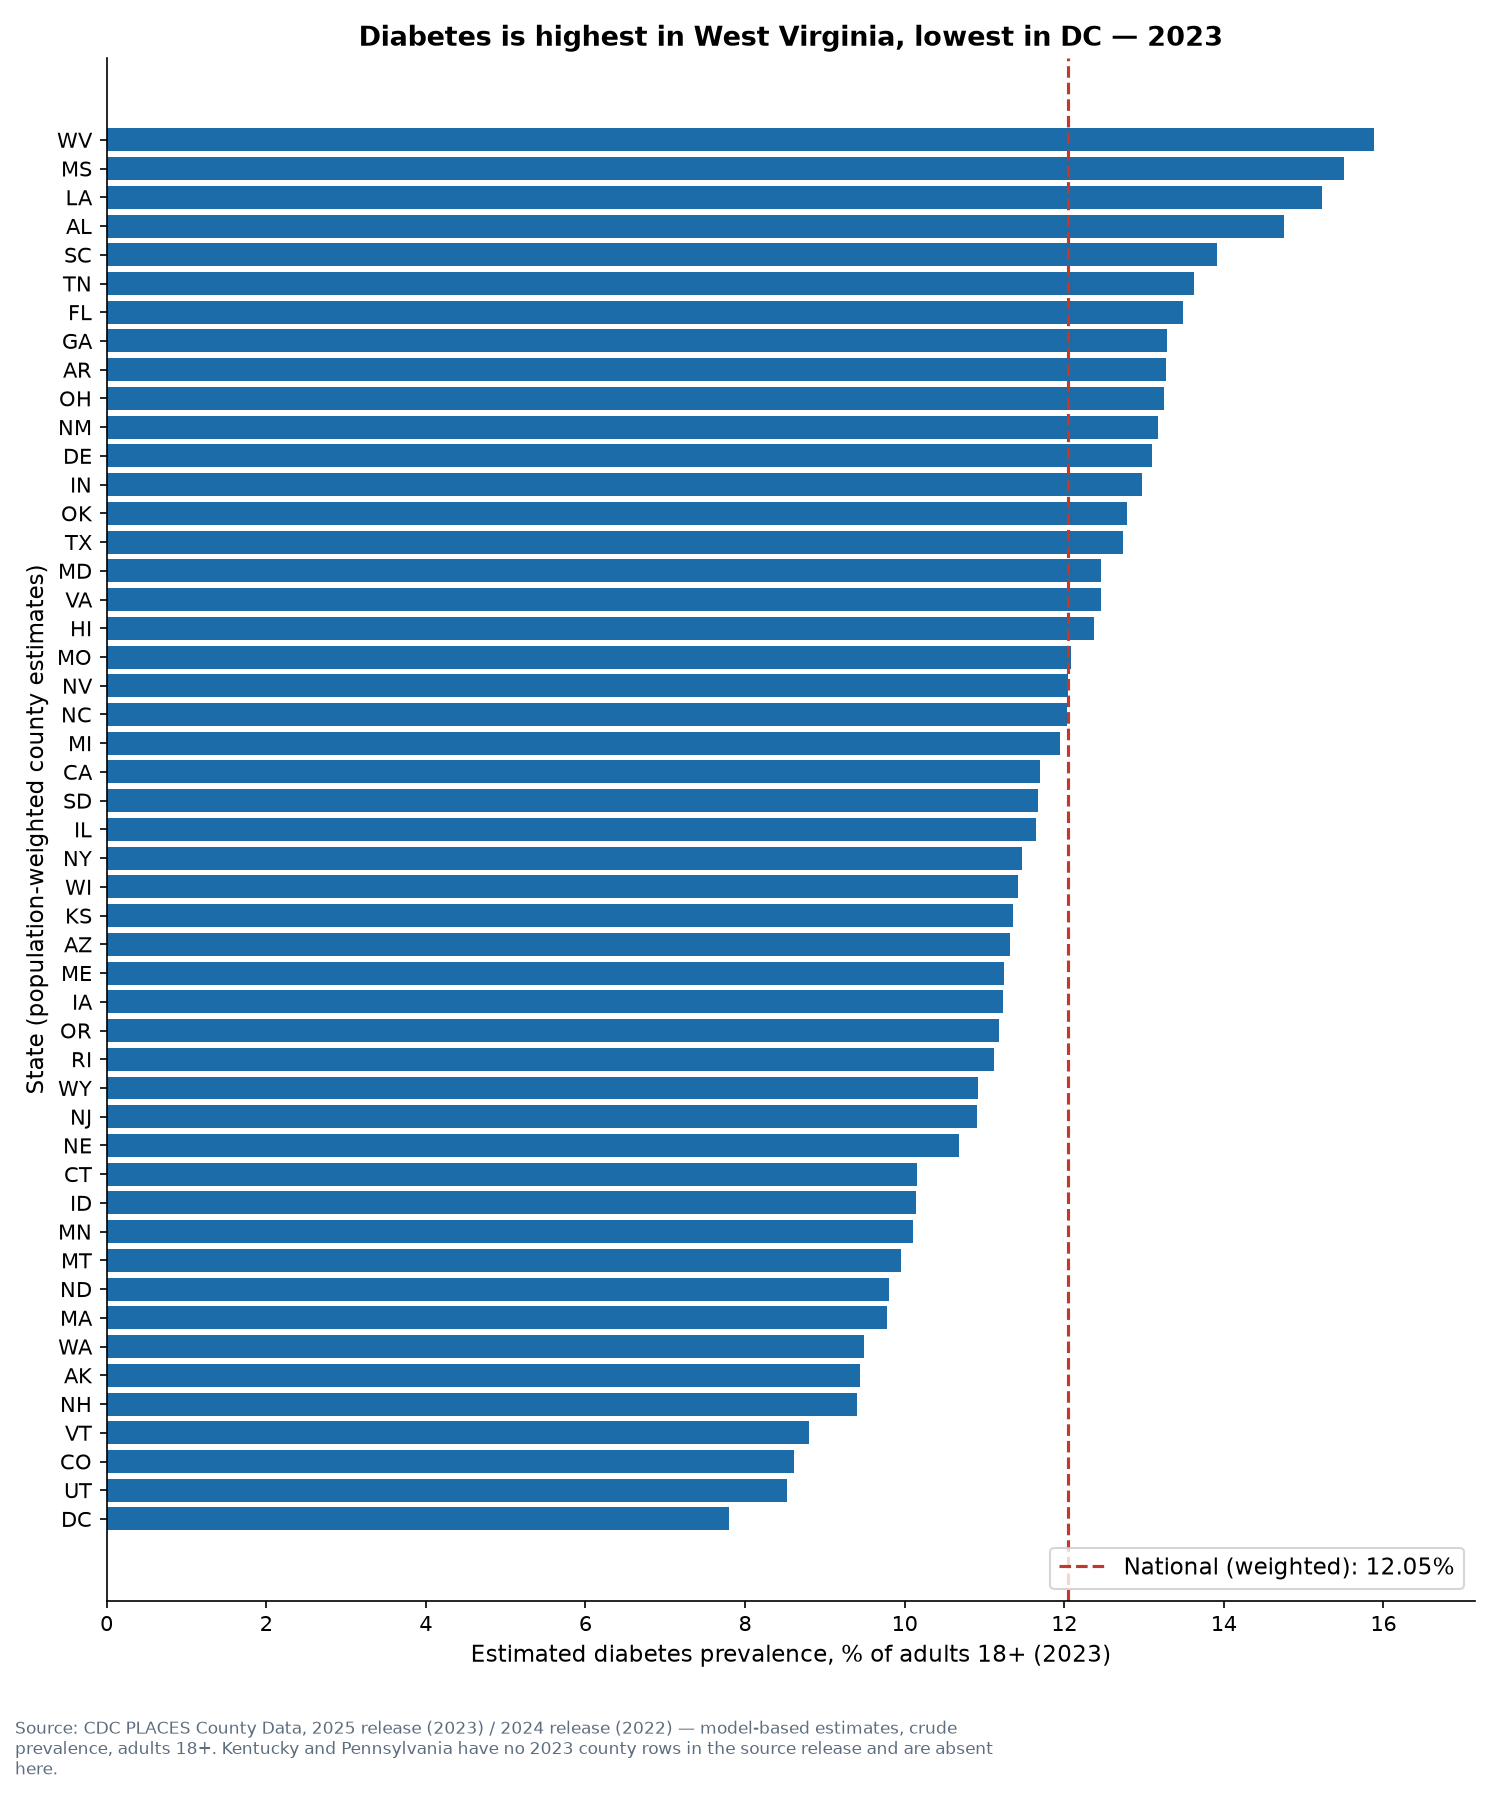

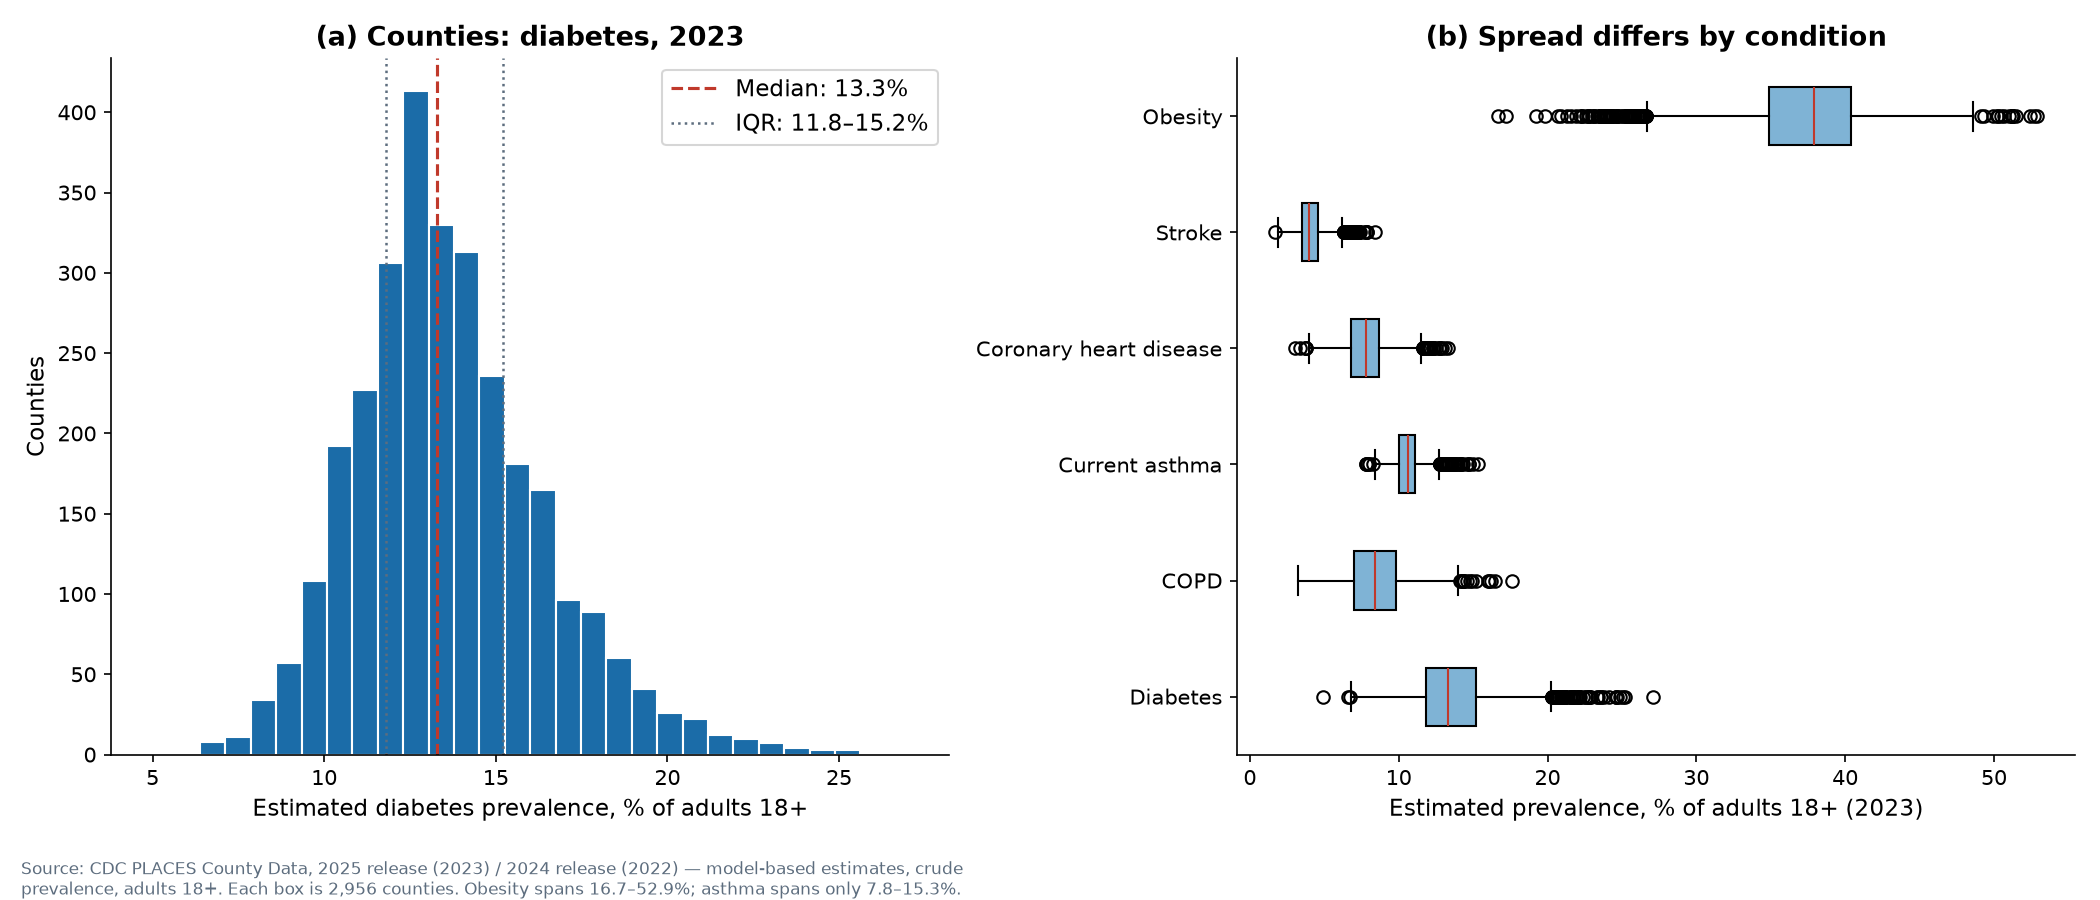

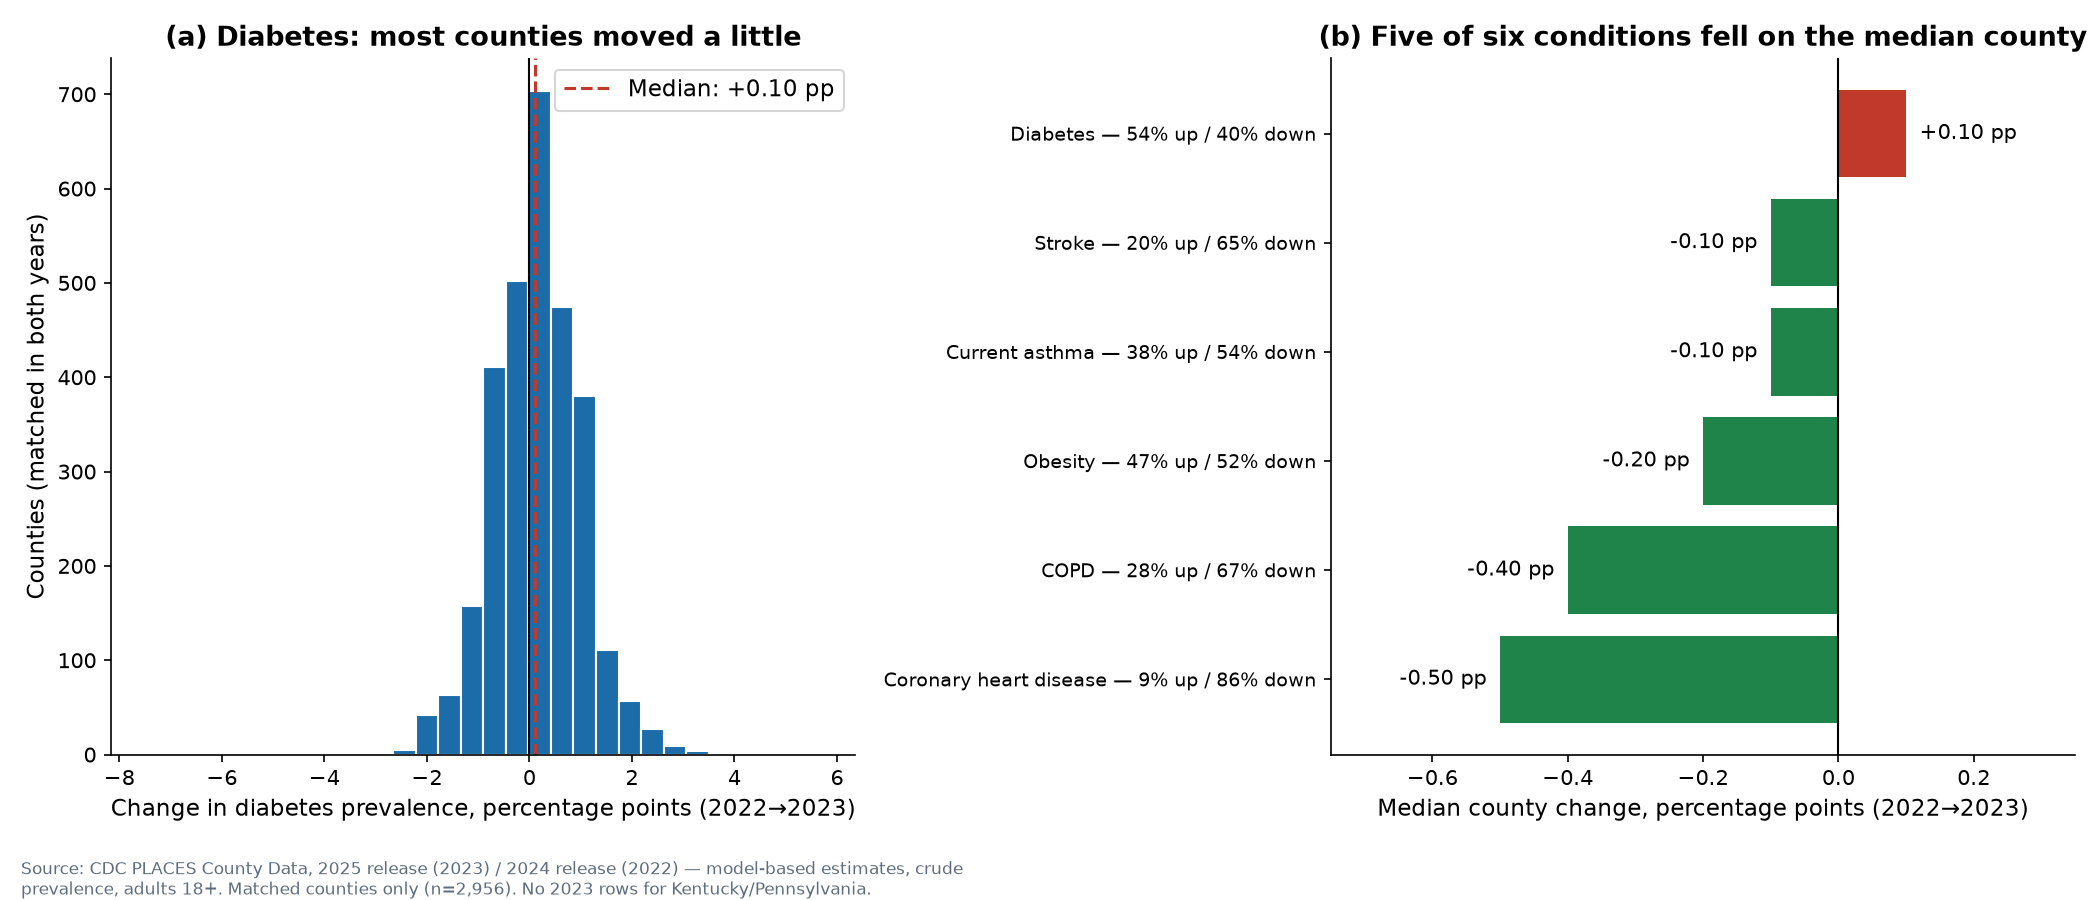

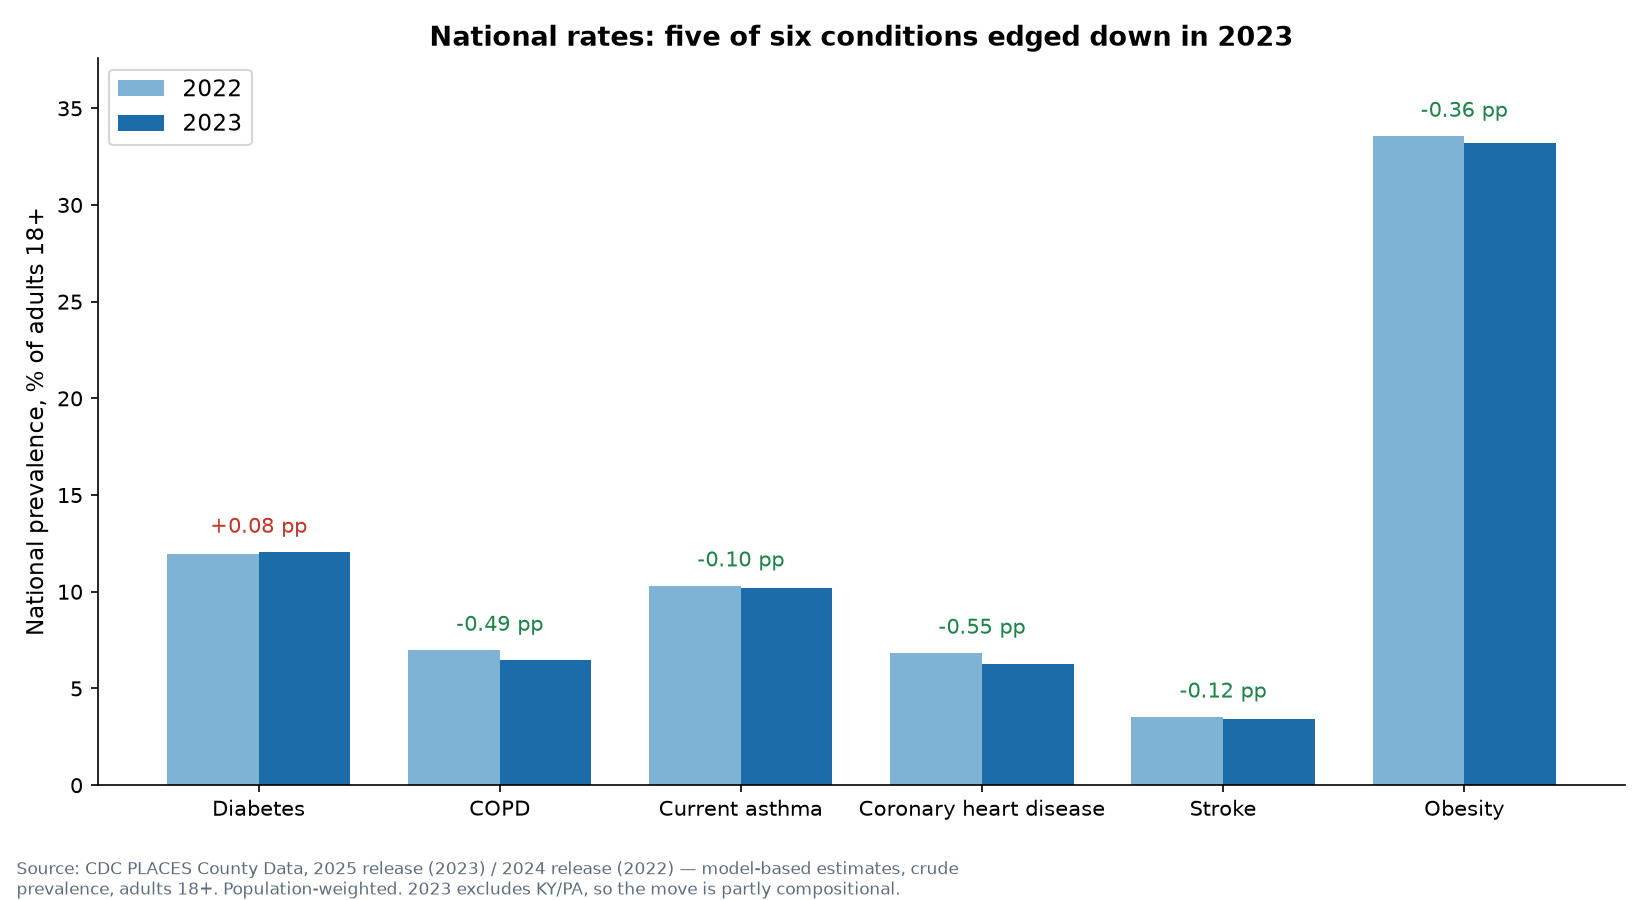

In [6]:
from IPython.display import Image, display
for name in ["01_state_ranking.png", "02_county_distribution.png",
             "03_change_2022_2023.png", "04_measure_comparison.png"]:
    display(Image(filename=str(ROOT / "outputs" / "charts" / name)))

## Limitations

- Model-based estimates from survey data, not counted cases; every county value carries a confidence interval (median width 0.8–15.3 pp depending on the condition).
- The 2025 release (2023) has no rows for Kentucky or Pennsylvania, so national 2022→2023 moves mix real change with a coverage change; the matched-county median is the cleaner year-over-year signal.
- Crude rates only: comparisons with age-adjusted figures will differ (see the Tangipahoa example, 14.6% vs 13.5%).
- County rankings are a starting point for questions, not a health league table.